# LBL sobre HARPS, LHS 1140

Extrae velocidades radiales con LBL (line-by-line, Artigau et al. 2022) a partir de los **e2ds_A** de HARPS bajados en el notebook de descarga. Se usa **INSTRUMENT="HARPS"** y **DATA_SOURCE="ORIG"** sobre **LHS1140_HARPS/science/LHS1140/**, con el blaze **HARPS_BLAZE_A_72.fits**.

**Resultado:** 293 espectros, RMS de 6.05 m/s y error mediano de 2.84 m/s. Con S/N mayor o igual que 10 quedan 207 espectros, RMS de 5.41 m/s. La tabla queda en Drive (**resultados_LBL/completa/**) y es la entrada del notebook de analisis de RV.

**Orden de uso:** primero **MODO_PRUEBA = True** (3 espectros, unos 15 min la primera vez porque baja unos 360 MB de modelos). Si da una dispersion de unos 6 m/s, pon **MODO_PRUEBA = False** y corre de nuevo desde la seccion Copiar los datos de Drive. La corrida completa tarda de 2.5 a 3 h.

**Requisito:** runtime de Python 3.12 (LBL 0.67.008 declara **>=3.12,<3.13**). LBL no esta en PyPI y se instala desde GitHub.

**Blaze:** el header de cada **e2ds** pide el blaze de su noche (147 archivos distintos), pero esos archivos no estan en el archivo de ESO. Se uso **HARPS_BLAZE_A_72.fits** del taller de velocidades radiales con LBL del semillero COSMIA-UdeA (Camilo Ospinal), por recomendacion del lider del semillero. Es una calibracion con lampara de tungsteno del 19 de marzo de 2016 (programa 60.A-9036(A) de ESO), dentro del rango de las observaciones (noviembre de 2015 a enero de 2018). No depende de la estrella, pero no es el blaze de cada noche, y no se midio cuanto afecta esto a las velocidades.

**Plantilla:** con **OBJECT_COMPARISON=[OBJETO]** la plantilla se construye con los espectros de LHS 1140, no con otra estrella. Por eso la tabla final se llama **lbl_LHS1140_tc_LHS1140_tc.rdb** (objeto y plantilla).

**Notas:**
- No hacen falta los **wave_A**: LBL arma la longitud de onda con las 288 claves **ESO DRS CAL TH COEFF LL*** del header de cada **e2ds**.
- **SNR_THRESHOLD**: LBL salta los espectros con S/N(orden 47) por debajo del umbral (10 por defecto). Con 5 entran los 293. El corte a S/N mayor o igual que 10 se hace despues, en la tabla de resultados, no en LBL.
- Si la corrida completa se corta, vuelve a correr la seccion Correr LBL: con **SKIP_LBL_COMPUTE=True** salta los espectros ya calculados (telluclean y la plantilla se rehacen, unos 60 min).

**Limitaciones:**
- Se usa un solo blaze para todas las epocas (**BLAZE_POR_NOCHE=False**), no el de cada noche.
- **TEFF = 3213** K solo elige la mascara de lineas. Para el analisis fisico de la estrella se usa Teff = 3096 +- 48 K (Cadieux et al. 2024).

**Referencias:**
- Artigau et al. 2022, AJ 164, 84.
- Cadieux et al. 2024, ApJL 960, L3.
- COSMIA-UdeA, Taller de velocidades radiales con LBL, GitHub, https://github.com/COSMIA-UdeA/Taller-Velocidades-Radiales-LBL, consultado el 22 de noviembre de 2026.
- LBL, https://github.com/njcuk9999/lbl.

**Orden entre notebooks:** primero el notebook de descarga de HARPS (deja science/, calib/ y el blaze en Drive), despues este, y luego el analisis de RV, que lee el CSV que se guarda en la ultima seccion. Dentro de este notebook las celdas van de arriba hacia abajo; solo se repite desde Copiar los datos de Drive al pasar de MODO_PRUEBA a la corrida completa.

## Instalar LBL desde GitHub

LBL no esta en PyPI. Se fija el commit para que la corrida sea reproducible. La instalacion avisa de conflictos con paquetes de Colab (ipython, pandas, requests); no afectan a LBL, que corre en un proceso aparte.

In [ ]:
COMMIT = "dbcd813e82c88a8ee873918a5c0176e5b878137a" # HEAD de GitHub el 2026-11-20 (LBL 0.67.008)
!pip install -q git+https://github.com/njcuk9999/lbl.git@{COMMIT}

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.5/377.5 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.5/825.5 kB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 112.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 102.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

**Nota:** reiniciar el notebook despues de instalar LBL (Entorno de ejecucion, Reiniciar sesion), porque la instalacion actualiza numpy.

### Comprobar la version instalada
Se comprueba en un proceso nuevo, igual que el wrap de la seccion Correr LBL.

In [ ]:
!python -c "import lbl, numpy, astropy; print('LBL', lbl.__version__, '| numpy', numpy.__version__, '| astropy', astropy.__version__)"

LBL 0.67.008 | numpy 2.3.3 | astropy 7.2.0


## Importaciones

### Importamos librerias

In [ ]:
import json
import shutil
import socket
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from astropy.io import fits
from google.colab import drive

### Servidores de modelos
Solo informativo: comprueba que los servidores de los modelos responden.

In [ ]:
# solo informativo: si un servidor no responde, la celda se detiene con el error
r = requests.head("http://206.12.93.77/ari/data/lbl/models/tapas_lbl.fits", timeout=20, allow_redirects=True)
print("TAPAS + gradientes responde, status", r.status_code)
socket.create_connection(("phoenix.astro.physik.uni-goettingen.de", 21), timeout=20).close()
print("PHOENIX (FTP) responde")

TAPAS + gradientes responde, status 200
PHOENIX (FTP) responde


## Parametros y Drive

In [ ]:
drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive/LHS1140_HARPS") # carpeta con science, calib y el blaze
OBJETO = "LHS1140"
TEFF = 3213 # K, solo elige la mascara de lineas (en el analisis se usa 3096 K), valor elegido en este trabajo
SNR_THRESHOLD = 5 # LBL usa 10 por defecto, valor elegido en este trabajo

MODO_PRUEBA = False # true: 3 espectros, False: todos
BLAZE_POR_NOCHE = False # false: un solo blaze para todo, True: los 147 blazes de calib/ (LBL toma el nombre de ESO DRS BLAZE FILE)
DATA_DIR_EN_DRIVE = True # true: DATA_DIR en Drive (mas lento, pero sobrevive a una desconexion)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Carpeta de trabajo
Prueba y corrida completa van en carpetas distintas para que no se mezclen. Tambien se revisa la version de Python.

In [ ]:
if MODO_PRUEBA:
    corrida = "prueba"
else:
    corrida = "completa"

if DATA_DIR_EN_DRIVE:
    base = DRIVE / "lbl_data"
else:
    base = Path("/content/lbl_data")

DATA_DIR = base / corrida
DATA_DIR.mkdir(parents=True, exist_ok=True)

v = sys.version_info
print("Python", v.major, v.minor, v.micro, "| DATA_DIR =", DATA_DIR)
if (v.major, v.minor) != (3, 12):
    print("Usa Python 3.12: Entorno de ejecucion, Cambiar tipo de entorno, version 2026.07, Reconectar")

Python 3 12 13 | DATA_DIR = /content/drive/MyDrive/LHS1140_HARPS/lbl_data/completa


## Copiar los datos de Drive a **DATA_DIR**

In [ ]:
K_SNR = "ESO DRS SPE EXT SN47"
K_BLAZE = "ESO DRS BLAZE FILE"
BLAZE_UNICO = "HARPS_BLAZE_A_72.fits"

sci_src = DRIVE / "science" / OBJETO
cal_src = DRIVE / "calib"
sci_dst = DATA_DIR / "science" / OBJETO
cal_dst = DATA_DIR / "calib"
mod_dst = DATA_DIR / "models"
for d in (sci_dst, cal_dst, mod_dst):
    d.mkdir(parents=True, exist_ok=True)

todos = sorted(sci_src.glob("*e2ds_A.fits"))
print(len(todos), "e2ds en Drive")

293 e2ds en Drive


### Espectros a copiar
En modo prueba se toman 3 espectros de los dias de la prueba local anterior. Si no estan, se toman 3 repartidos en el tiempo y con S/N suficiente (12 candidatos y S/N de al menos 10, valores elegidos en este trabajo). En la corrida completa se toman todos.

In [ ]:
if MODO_PRUEBA:
    elegidos = []
    for dia in ("2015-11-23", "2015-11-27", "2015-11-28"):
        cand = sorted(sci_src.glob(f"HARPS.{dia}T*_e2ds_A.fits"))
        if len(cand) > 0:
            elegidos.append(cand[0])
    if len(elegidos) < 3:
        elegidos = []
        for pos in np.linspace(0, len(todos) - 1, 12):
            snr = fits.getheader(todos[int(pos)]).get(K_SNR, 0)
            if snr >= max(SNR_THRESHOLD, 10):
                elegidos.append(todos[int(pos)])
            if len(elegidos) == 3:
                break
else:
    elegidos = todos

### Copiar los espectros
Solo se copian los que todavia no estan en DATA_DIR.

In [ ]:
for f in elegidos:
    if not (sci_dst / f.name).exists():
        shutil.copy2(f, sci_dst / f.name)

### Blaze
Con BLAZE_POR_NOCHE en False se copia el blaze unico (ver la nota de blaze al inicio). Con True se copian los blazes de cada noche que existan en calib/ de Drive.

In [ ]:
if BLAZE_POR_NOCHE:
    faltan = []
    for f in sci_dst.glob("*e2ds_A.fits"):
        nombre_blaze = fits.getheader(f).get(K_BLAZE)
        if not (cal_dst / nombre_blaze).exists():
            if (cal_src / nombre_blaze).exists():
                shutil.copy2(cal_src / nombre_blaze, cal_dst / nombre_blaze)
            else:
                faltan.append(nombre_blaze)
    print("Blazes por noche en calib/:", len(list(cal_dst.glob("*_blaze_A.fits"))), "| faltan:", faltan)
else:
    origen = None
    for ruta in (DRIVE / BLAZE_UNICO, Path("/content") / BLAZE_UNICO):
        if ruta.exists():
            origen = ruta
            break
    if origen is None:
        print("No encuentro HARPS_BLAZE_A_72.fits (ni en LHS1140_HARPS ni en /content)")
    else:
        shutil.copy2(origen, cal_dst / BLAZE_UNICO)
        print("Blaze unico:", cal_dst / BLAZE_UNICO)

Blaze unico: /content/drive/MyDrive/LHS1140_HARPS/lbl_data/completa/calib/HARPS_BLAZE_A_72.fits


### Modelos
Si ya se bajaron en una corrida anterior, se copian desde Drive para no bajar otra vez unos 360 MB.

In [ ]:
if (DRIVE / "models").exists():
    for f in (DRIVE / "models").glob("*"):
        if f.is_file() and not (mod_dst / f.name).exists():
            shutil.copy2(f, mod_dst / f.name)
print("Espectros en DATA_DIR:", len(list(sci_dst.glob("*e2ds_A.fits"))), "| modelos locales:", len(list(mod_dst.glob("*"))))

Espectros en DATA_DIR: 293 | modelos locales: 10


## QC de lo que va a leer LBL

Debe haber un solo objeto, 288 coeficientes de wave por espectro y blaze finito. Con **SNR_THRESHOLD** = 5 ningun espectro queda por debajo del umbral.

In [ ]:
filas = []
for f in sorted(sci_dst.glob("*e2ds_A.fits")):
    h = fits.getheader(f)
    coefs = [k for k in h if k.startswith("ESO DRS CAL TH COEFF LL")]
    filas.append({"archivo": f.name,
                  "objeto": h.get("ESO OBS TARG NAME"),
                  "snr47": h.get(K_SNR),
                  "n_coef_wave": len(coefs),
                  "rjd": h.get("ESO DRS BJD") - 2400000, # fecha juliana reducida: BJD menos 2400000
                  "berv": h.get("ESO DRS BERV"),
                  "blaze": h.get(K_BLAZE)})
hdr_df = pd.DataFrame(filas)

### Chequeos
Si algo no cumple, se avisa al final con REVISAR.

In [ ]:
print(len(hdr_df), "espectros | objetos:", hdr_df["objeto"].unique())
print("Coeficientes de wave (debe ser 288):", hdr_df["n_coef_wave"].unique())
if not BLAZE_POR_NOCHE:
    blz = fits.getdata(cal_dst / BLAZE_UNICO) # igual que LBL: primer HDU con datos
    print("Blaze:", blz.shape, "| finito:", np.isfinite(blz).all())
print("S/N47: min", round(hdr_df["snr47"].min(), 1), "| mediana", round(hdr_df["snr47"].median(), 1), "| max", round(hdr_df["snr47"].max(), 1))
print("Con S/N < 10:", (hdr_df["snr47"] < 10).sum(), "| con S/N < SNR_THRESHOLD (LBL los salta):", (hdr_df["snr47"] < SNR_THRESHOLD).sum())
if not (hdr_df["n_coef_wave"] == 288).all() or not (hdr_df["objeto"] == OBJETO).all():
    print("REVISAR: hay espectros de otro objeto o sin los 288 coeficientes")

293 espectros | objetos: ['LHS1140']
Coeficientes de wave (debe ser 288): [288]
Blaze: (72, 4096) | finito: True
S/N47: min 5.6 | mediana 11.8 | max 17.5
Con S/N < 10: 86 | con S/N < SNR_THRESHOLD (LBL los salta): 0


## Correr LBL

Se corre en un proceso aparte (**lbl_wrap**) con los parametros guardados en un JSON. Con **OBJECT_COMPARISON=[OBJETO]** la plantilla se hace con los propios datos.

In [ ]:
rparams = dict(
    INSTRUMENT="HARPS",
    DATA_SOURCE="ORIG", # e2ds del DRS original (no usar ESO: es HARPS_ESO y ignoraria el blaze)
    DATA_DIR=str(DATA_DIR),
    OBJECT_SCIENCE=[OBJETO],
    OBJECT_COMPARISON=[OBJETO], # plantilla con los propios datos
    DATA_TYPES=["SCIENCE"],
    OBJECT_TEFF=[TEFF],
    BLAZE_FILE=None if BLAZE_POR_NOCHE else BLAZE_UNICO,
    BLAZE_CORRECTED=False, # los e2ds_A no vienen corregidos por blaze
    INPUT_FILE="*e2ds_A.fits", # solo fibra A
    SNR_THRESHOLD=SNR_THRESHOLD,
    RUN_LBL_TELLUCLEAN=True,
    RUN_LBL_TEMPLATE=True,
    RUN_LBL_MASK=True,
    RUN_LBL_COMPUTE=True,
    RUN_LBL_COMPILE=True,
    # SKIP_* significa saltar si el resultado ya existe, asi se puede reanudar
    SKIP_LBL_TEMPLATE=False,
    SKIP_LBL_MASK=False,
    SKIP_LBL_COMPUTE=True,
    SKIP_LBL_COMPILE=False,
    VERBOSE=2,
    PLOT=False,
)

### Archivos para el proceso aparte
Se guardan los parametros en un JSON y se escribe un script minimo que llama a **lbl_wrap**.

In [ ]:
RUN = Path("/content/lbl_run")
RUN.mkdir(exist_ok=True)
PARAMS_JSON = RUN / "rparams.json"
RUNNER = RUN / "run_lbl.py"
PARAMS_JSON.write_text(json.dumps(rparams, indent=1))
RUNNER.write_text("import json, sys\nfrom lbl import lbl_wrap\nlbl_wrap(json.load(open(sys.argv[1])))\n")

81

### Correr LBL
Es la parte lenta. Con **SKIP_LBL_COMPUTE=True** reutiliza los espectros ya calculados.

In [ ]:
!python {RUNNER} {PARAMS_JSON}

Se truncaron las últimas líneas 5000 del resultado de transmisión.
2026-11-26 13:00:07.281|G| 	Iteration 3
2026-11-26 13:00:07.282|G| 	--------------------------------------------------
2026-11-26 13:00:14.484|G| 		stdev_meas/stdev_pred = 1.04
2026-11-26 13:00:14.486|G| 		Iteration 2: bulk error: 2.18 m/s rv = 14579.78 m/s
2026-11-26 13:00:14.487|G| 		Iteration duration: 7.2030
2026-11-26 13:00:14.488|G| 		RV = -0.04 m/s, sigma = 2.18 m/s
2026-11-26 13:00:14.492|G| 	--------------------------------------------------
2026-11-26 13:00:14.493|G| Compute RV converged in 3 steps
2026-11-26 13:00:15.483|G| Writing reference table to: /content/drive/MyDrive/LHS1140_HARPS/lbl_data/completa/lblrv/LHS1140_tc_LHS1140_tc/HARPS.2016-12-13T01:39:34.133_e2ds_A_LHS1140_tc_LHS1140_tc_lbl.fits
2026-11-26 13:00:16.748|I| *******************************************************************************
2026-11-26 13:00:16.749|I| Processing file 143 / 293   (150 left)
2026-11-26 13:00:16.749|I| *************

## Resultados

Lectura de la tabla final (**.rdb**), RMS con y sin el corte S/N mayor o igual que 10 y grafica de la RV.

In [ ]:
rdb_dir = DATA_DIR / "lblrdb"
rdb = rdb_dir / ("lbl_" + OBJETO + "_tc_" + OBJETO + "_tc.rdb")
print("Tabla:", rdb.name, "| existe:", rdb.exists())

Tabla: lbl_LHS1140_tc_LHS1140_tc.rdb | existe: True


### Leer la tabla
LBL nombra la tabla con el objeto y la plantilla. Como la plantilla es de LHS 1140, el nombre repite el objeto.

In [ ]:
rv = pd.read_csv(rdb, sep="\t", skiprows=[1]) # la linea 2 de un .rdb son guiones
for c in rv.columns:
    if c != "DATE-OBS":
        rv[c] = pd.to_numeric(rv[c], errors="coerce")
rv = rv.rename(columns={"HIERARCH ESO DRS BERV": "berv", "HIERARCH ESO DRS SPE EXT SN47": "snr47"})
rv = rv.sort_values("rjd").reset_index(drop=True)

### RMS y error mediano
El RMS es la desviacion estandar de las velocidades respecto a su media ponderada con el inverso del error al cuadrado.

In [ ]:
def resumen(d, etiqueta):
    w = 1 / d["svrad"] ** 2
    media = np.sum(w * d["vrad"]) / np.sum(w)
    rms = (d["vrad"] - media).std(ddof=1)
    print(etiqueta, "| N =", len(d), "| RMS =", round(rms, 2), "m/s | error mediano =", round(d["svrad"].median(), 2), "m/s")

resumen(rv, "todos")
resumen(rv[rv["snr47"] >= 10], "S/N >= 10")

todos | N = 293 | RMS = 6.05 m/s | error mediano = 2.84 m/s
S/N >= 10 | N = 207 | RMS = 5.41 m/s | error mediano = 2.59 m/s


### Comparacion con la prueba local
Solo en modo prueba.

In [ ]:
if MODO_PRUEBA:
    # valores de la prueba local anterior de este trabajo
    print("Referencia local (2015-11-23/27/28): -13620.59 / -13608.66 / -13616.87 m/s, dispersion 6.1 m/s")
    print("Si salieron otros espectros, compara la dispersion y no los valores")
    print(rv[["DATE-OBS", "vrad", "svrad", "berv", "snr47"]])

### Grafica de la RV
Velocidad radial menos su mediana, con S/N mayor o igual que 10 en azul y menor que 10 en rojo.

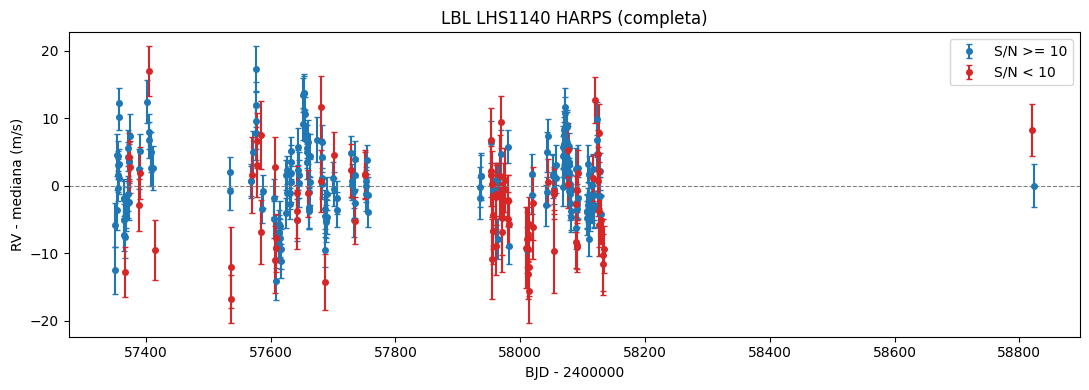

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(figsize=(11, 4))
mediana = rv["vrad"].median()
grupos = ((rv["snr47"] >= 10, "C0", "S/N >= 10"), (rv["snr47"] < 10, "C3", "S/N < 10"))
for mascara, color, etiqueta in grupos:
    d = rv[mascara]
    if len(d) > 0:
        ax.errorbar(d["rjd"], d["vrad"] - mediana, d["svrad"], fmt="o", ms=4, capsize=2, color=color, label=etiqueta)
ax.axhline(0, color="gray", ls="--", lw=0.8)
ax.set_xlabel("BJD - 2400000")
ax.set_ylabel("RV - mediana (m/s)")
ax.set_title("LBL " + OBJETO + " HARPS (" + corrida + ")")
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "rv_LHS1140.png", dpi=150)
plt.show()

## Respaldo en Drive

Se guardan los resultados y los modelos descargados, para no bajarlos otra vez.

In [ ]:
out = DRIVE / "resultados_LBL" / corrida
out.mkdir(parents=True, exist_ok=True)
cols = []
for c in ("DATE-OBS", "rjd", "vrad", "svrad", "berv", "snr47", "CRX"):
    if c in rv.columns:
        cols.append(c)
tabla = rv[cols].copy()
tabla["bjd"] = tabla["rjd"] + 2400000.0
tabla.to_csv(out / "RV_LHS1140.csv", index=False)
shutil.copy2(DATA_DIR / "rv_LHS1140.png", out / "rv_LHS1140.png")
for p in rdb_dir.glob("*.rdb"):
    shutil.copy2(p, out / p.name)

### Modelos
Se respaldan los modelos descargados para no bajarlos otra vez.

In [ ]:
(DRIVE / "models").mkdir(exist_ok=True)
for f in mod_dst.glob("*"):
    if f.is_file() and not (DRIVE / "models" / f.name).exists():
        shutil.copy2(f, DRIVE / "models" / f.name)
print("Guardado en", out, "| modelos en", DRIVE / "models")

Guardado en /content/drive/MyDrive/LHS1140_HARPS/resultados_LBL/completa | modelos en /content/drive/MyDrive/LHS1140_HARPS/models
